# Émotion — Donner une âme au message

Ce notebook produit des **indices lexicaux exploratoires** pour décrire le contenu des témoignages et guider les paramètres de l'avatar. Ces résultats ne sont pas des annotations psychologiques et ne remplacent pas une validation humaine.

- Aucun classifieur général positif/neutre/négatif n'est utilisé : le modèle testé auparavant confondait parfois une description de souffrance ou un contexte difficile avec l'intention de la personne.
- Les dimensions sont des indices lexicaux en français, pas des émotions certaines.
- Sans indice détecté, le résultat est explicitement **non déterminé**.
- Les paramètres de l'avatar sont bornés dans leurs plages documentées.

Input : data/processed/corpus.parquet  
Output : data/processed/corpus_with_emotions.parquet et statistiques associées.

In [1]:
import sys
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display, HTML

PROJECT_ROOT = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "src/analysis/emotion.py").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Impossible de localiser la racine du projet depuis le notebook.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.analysis.emotion import (
    FACE_MAP,
    LEXICON,
    NO_EVIDENCE,
    VOICE_MAP,
    compute_avatar_params,
    dominant_dimension,
    score_dimensions,
)

plt.rcParams.update({"font.size": 12, "figure.facecolor": "white"})
sns.set_palette("Set2")

In [2]:
# Charger le corpus propre
corpus = pd.read_parquet(PROJECT_ROOT / "data/processed/corpus.parquet")
print(f"Corpus : {len(corpus):,} messages")
print(f"Avec témoignage : {corpus['testimony'].notna().sum():,}")

Corpus : 8,707 messages
Avec témoignage : 8,707


---
## Pourquoi il n'y a pas d'étiquette « négatif »

Le classifieur multilingue testé précédemment avait été entraîné sur des messages Twitter, pas sur des témoignages de personnes souhaitant accueillir. Il attribuait par exemple une polarité négative à « Je veux venir en aide aux Syriens » et à une proposition d'hébergement. Ces étiquettes à score élevé n'étaient donc pas cohérentes avec l'intention exprimée.

Le notebook ne produit plus de classement positif/neutre/négatif. Il conserve des indices contextuels transparents, et signale **non déterminée** toute dimension sans indice lexical. Pour réintroduire une polarité, il faudra annoter un échantillon de ce corpus et évaluer un modèle sur ces annotations.

---
## 2. Indices émotionnels contextuels (lexique français)

Le classifieur j-hartmann/emotion-english-distilroberta-base a été retiré : il est entraîné en anglais et ses étiquettes (disgust, anger…) ne sont pas fiables sur des témoignages français. Les dimensions ci-dessous sont des indices lexicaux heuristiques, pas des émotions certaines de la personne. La polarité négative et l'intention solidaire sont deux informations distinctes.

---
### Dimensions du lexique

Les scores comptent des indices lexicaux en français, avec frontières de mots, normalisation des accents et détection locale simple de négation. Ils restent heuristiques et doivent être validés par lecture humaine.

| Dimension | Indices recherchés | Effet avatar |
|-----------|-------------------|--------------|
| **Solidarité** | Engagement collectif, entraide | Regard direct, voix ferme et chaleureuse |
| **Empathie** | Compassion, compréhension de la souffrance | Regard doux, voix plus lente et posée |
| **Urgence** | Choc, besoin d'agir maintenant | Sourcils relevés, débit plus rapide |
| **Chaleur** | Accueil, partage, famille | Sourire, voix chaleureuse et enveloppante |
| **Tristesse** | Références lexicales à la souffrance | Regard baissé, voix basse, pauses |
| **Espoir** | Optimisme, croire au changement | Yeux lumineux, voix montante |
| **Détermination** | Décision ferme, volonté d'agir | Mâchoire serrée, voix posée et décidée |
| **Indignation** | Colère face à l'injustice | Sourcils froncés, voix plus forte |

In [3]:
# Calcul des scores lexicaux français
text_for_dimensions = corpus["testimony"].fillna("").astype(str).str.strip()
text_for_dimensions = text_for_dimensions.where(
    text_for_dimensions.ne(""),
    corpus["full_text"].fillna("").astype(str).str.strip(),
)
dim_df = pd.DataFrame(
    text_for_dimensions.apply(score_dimensions).tolist(),
    index=corpus.index,
).reindex(columns=list(LEXICON), fill_value=0.0)

for dimension in LEXICON:
    corpus[f"dim_{dimension}"] = dim_df[dimension]

dim_cols = [f"dim_{dimension}" for dimension in LEXICON]
corpus["dominant_dimension"] = dim_df.apply(dominant_dimension, axis=1)

print("Indices contextuels dominants :")
print(corpus["dominant_dimension"].value_counts())
print(
    "Messages sans indice lexical détecté : "
    f"{corpus['dominant_dimension'].eq(NO_EVIDENCE).sum():,}"
)

Indices contextuels dominants :
dominant_dimension
non_determinee    4111
chaleur           1971
solidarite        1167
empathie           555
espoir             349
urgence            301
tristesse          162
determination       62
indignation         29
Name: count, dtype: int64
Messages sans indice lexical détecté : 4,111


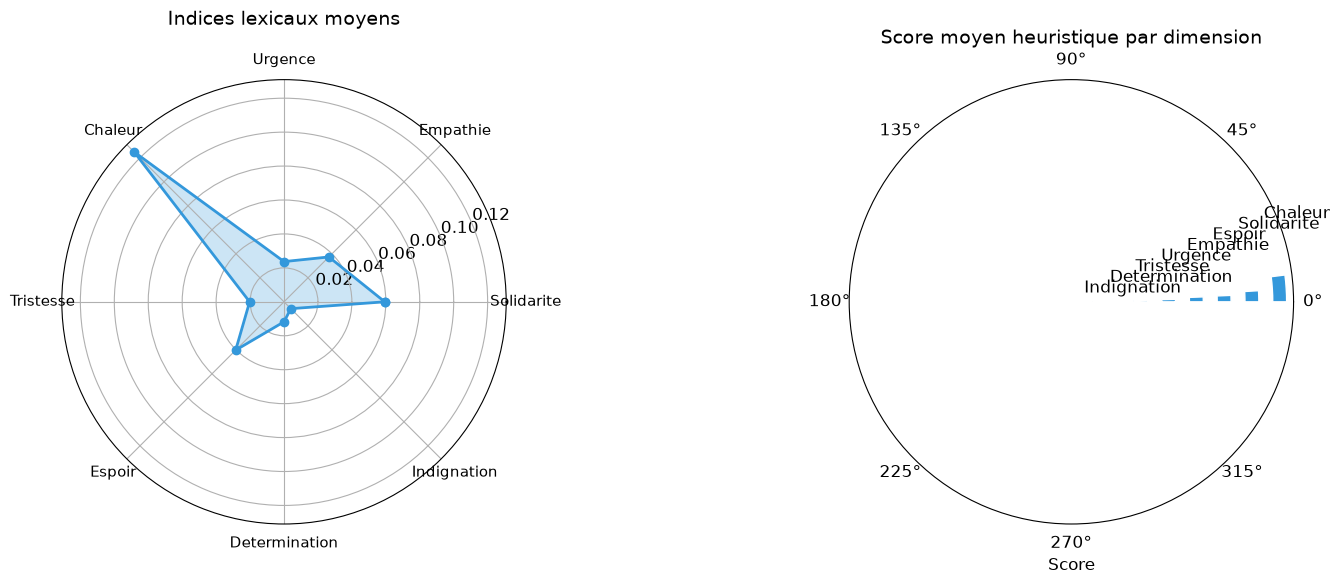

In [4]:
# Profil moyen des dimensions contextuelles
dims = list(LEXICON.keys())
values = [corpus[f"dim_{dimension}"].mean() for dimension in dims]

angles = np.linspace(0, 2 * np.pi, len(dims), endpoint=False).tolist()
values_plot = values + [values[0]]
angles += [angles[0]]

fig, axes = plt.subplots(1, 2, figsize=(16, 6), subplot_kw={"polar": True})
ax = axes[0]
ax.fill(angles, values_plot, alpha=0.25, color="#3498db")
ax.plot(angles, values_plot, "o-", linewidth=2, color="#3498db")
ax.set_xticks(angles[:-1])
ax.set_xticklabels([dimension.capitalize() for dimension in dims], fontsize=11)
ax.set_title("Indices lexicaux moyens", fontsize=14, pad=20)

ax2 = axes[1]
dim_means = pd.Series(
    {dimension.capitalize(): corpus[f"dim_{dimension}"].mean() for dimension in dims}
).sort_values()
dim_means.plot(kind="barh", ax=ax2, color="#3498db", edgecolor="white")
ax2.set_title("Score moyen heuristique par dimension", fontsize=14)
ax2.set_xlabel("Score")

plt.tight_layout()
plt.show()

---
## 3. Mapping vers l'avatar

Les indices lexicaux sont normalisés en poids relatifs avant l'interpolation. En l'absence d'indice, les valeurs neutres sont conservées; chaque paramètre est borné dans la plage décrite.

In [5]:
# Appliquer les mappings définis dans src/analysis/emotion.py
avatar_params = corpus.apply(
    lambda row: compute_avatar_params(
        {dimension: row[f"dim_{dimension}"] for dimension in LEXICON}
    ),
    axis=1,
)
params_df = pd.DataFrame(avatar_params.tolist(), index=corpus.index)
corpus[params_df.columns] = params_df

parameter_ranges = {
    "voice_pitch": (-1, 1),
    "voice_speed": (0.5, 1.5),
    "voice_energy": (0, 1),
    "voice_warmth": (0, 1),
    "face_eyebrows": (-1, 1),
    "face_mouth": (-1, 1),
    "face_eyes": (0, 1),
    "face_gaze": (0, 1),
}
for parameter, (minimum, maximum) in parameter_ranges.items():
    assert corpus[parameter].between(minimum, maximum).all(), parameter

assert corpus["dominant_dimension"].ne(NO_EVIDENCE).any(), (
    "Des indices lexicaux sont détectés mais aucun profil avatar n'a été calculé."
)
assert any(corpus[parameter].nunique() > 1 for parameter in parameter_ranges), (
    "Les paramètres avatar sont constants malgré des indices lexicaux détectés."
)

print("Paramètres avatar calculés et bornés :")
for parameter, (minimum, maximum) in parameter_ranges.items():
    print(
        f"  {parameter:15s}: moyenne={corpus[parameter].mean():.3f}, "
        f"plage=[{corpus[parameter].min():.3f}, {corpus[parameter].max():.3f}] "
        f"(limites {minimum}, {maximum})"
    )

Paramètres avatar calculés et bornés :
  voice_pitch    : moyenne=0.022, plage=[-0.300, 0.400] (limites -1, 1)
  voice_speed    : moyenne=0.975, plage=[0.750, 1.200] (limites 0.5, 1.5)
  voice_energy   : moyenne=0.534, plage=[0.300, 0.900] (limites 0, 1)
  voice_warmth   : moyenne=0.663, plage=[0.200, 1.000] (limites 0, 1)
  face_eyebrows  : moyenne=0.112, plage=[-0.500, 0.600] (limites -1, 1)
  face_mouth     : moyenne=0.160, plage=[-0.500, 0.600] (limites -1, 1)
  face_eyes      : moyenne=0.623, plage=[0.300, 1.000] (limites 0, 1)
  face_gaze      : moyenne=0.692, plage=[0.300, 1.000] (limites 0, 1)


---
## 4. Résultat : messages prêts pour l'avatar

In [6]:
def show_emotion_card(row):
    """Affiche les indices contextuels et les paramètres d'un message."""
    sorted_dimensions = sorted(
        LEXICON, key=lambda dimension: row[f"dim_{dimension}"], reverse=True
    )
    dimensions_html = " ".join(
        f"<span style='background:#ecf0f1; padding:2px 8px; "
        f"border-radius:10px; margin:2px; font-size:12px;'>"
        f"{dimension} <b>{row[f'dim_{dimension}']:.2f}</b></span>"
        for dimension in sorted_dimensions[:4]
        if row[f"dim_{dimension}"] > 0
    ) or "Aucun indice lexical détecté"

    def bar(value, low=-1, high=1):
        percentage = min(max((value - low) / (high - low) * 100, 0), 100)
        return (
            "<div style='background:#ecf0f1; height:8px; border-radius:4px; "
            "width:120px; display:inline-block;'>"
            f"<div style='background:#3498db; height:8px; border-radius:4px; "
            f"width:{percentage:.0f}%;'></div></div>"
        )

    html = f"""
    <div style='border:1px solid #ddd; border-radius:8px; padding:16px; margin:16px 0; background:white; box-shadow:0 1px 3px rgba(0,0,0,0.1);'>
        <div style='font-weight:bold; color:#2c3e50; margin-bottom:10px;'>{row['id']}</div>
    """
    if pd.notna(row["testimony"]):
        text = str(row["testimony"])[:400].replace("\n", "<br>")
        if len(str(row["testimony"])) > 400:
            text += "…"
        html += f"<div style='font-style:italic; color:#34495e; margin:10px 0; line-height:1.5;'>❝ {text} ❞</div>"

    html += f"""
        <div style='margin-top:12px;'>
            <div style='font-size:12px; color:#7f8c8d; margin-bottom:4px;'>
                Indice contextuel dominant : <b>{row['dominant_dimension']}</b>
            </div>
            <div style='margin:6px 0;'>{dimensions_html}</div>
        </div>
        <div style='display:grid; grid-template-columns:1fr 1fr; gap:8px; margin-top:12px; font-size:12px; color:#555;'>
            <div>
                <b>Voix</b><br>
                Pitch: {row['voice_pitch']:.2f} {bar(row['voice_pitch'])}<br>
                Speed: {row['voice_speed']:.2f} {bar(row['voice_speed'], 0.5, 1.5)}<br>
                Energy: {row['voice_energy']:.2f} {bar(row['voice_energy'], 0, 1)}<br>
                Warmth: {row['voice_warmth']:.2f} {bar(row['voice_warmth'], 0, 1)}
            </div>
            <div>
                <b>Visage</b><br>
                Sourcils: {row['face_eyebrows']:.2f} {bar(row['face_eyebrows'])}<br>
                Bouche: {row['face_mouth']:.2f} {bar(row['face_mouth'])}<br>
                Yeux: {row['face_eyes']:.2f} {bar(row['face_eyes'], 0, 1)}<br>
                Regard: {row['face_gaze']:.2f} {bar(row['face_gaze'], 0, 1)}
            </div>
        </div>
    </div>
    """
    display(HTML(html))

# Afficher un échantillon des dimensions détectées, plus les cas non déterminés.
candidates = corpus[corpus["testimony_length"] > 80]
samples = candidates.groupby("dominant_dimension", group_keys=False).sample(
    n=1, random_state=123
)
sample_count = min(5, len(candidates))
if len(samples) < sample_count:
    remaining = candidates.drop(index=samples.index).sample(
        n=sample_count - len(samples), random_state=456
    )
    samples = pd.concat([samples, remaining])

for _, row in samples.iterrows():
    show_emotion_card(row)

---
## 5. Sauvegarder le corpus annoté

In [7]:
out_dir = PROJECT_ROOT / "data/processed"
out_dir.mkdir(parents=True, exist_ok=True)

corpus.to_parquet(out_dir / "corpus_with_emotions.parquet", index=False)
corpus.to_csv(out_dir / "corpus_with_emotions.csv", index=False)

avatar_config = {
    "voice_map": VOICE_MAP,
    "face_map": FACE_MAP,
    "emotion_dimensions": list(LEXICON),
    "lexicon": LEXICON,
    "emotion_method": "heuristic_french_context_lexicon",
    "sentiment_classifier": None,
}
with open(out_dir / "avatar_config.json", "w", encoding="utf-8") as file:
    json.dump(avatar_config, file, indent=2, ensure_ascii=False)

emotion_stats = {
    "sentiment_analysis": "Not produced: previous generic Twitter model was unreliable on this corpus.",
    "emotion_method": "Heuristic French context lexicon; requires human validation.",
    "dominant_dimensions": corpus["dominant_dimension"].value_counts().to_dict(),
    "messages_without_lexical_evidence": int(
        corpus["dominant_dimension"].eq(NO_EVIDENCE).sum()
    ),
    "mean_voice_params": {
        parameter: float(corpus[f"voice_{parameter}"].mean())
        for parameter in ("pitch", "speed", "energy", "warmth")
    },
    "mean_face_params": {
        parameter: float(corpus[f"face_{parameter}"].mean())
        for parameter in ("eyebrows", "mouth", "eyes", "gaze")
    },
    "mean_dimensions": {
        dimension: float(corpus[f"dim_{dimension}"].mean())
        for dimension in LEXICON
    },
}
with open(out_dir / "emotion_stats.json", "w", encoding="utf-8") as file:
    json.dump(emotion_stats, file, indent=2, ensure_ascii=False)

print(f"Corpus annoté sauvegardé : {len(corpus):,} messages")
print(f"  → {out_dir / 'corpus_with_emotions.parquet'}")
print(f"  → {out_dir / 'corpus_with_emotions.csv'}")
print(f"  → {out_dir / 'avatar_config.json'}")
print(f"  → {out_dir / 'emotion_stats.json'}")
print("Aucune polarité négative ou positive n'est inférée par un modèle générique.")

Corpus annoté sauvegardé : 8,707 messages
  → /Users/maxence/Télécom Paris  /3A/PROJET PRIM/A_FACE_TO_A_MESSAGE/data/processed/corpus_with_emotions.parquet
  → /Users/maxence/Télécom Paris  /3A/PROJET PRIM/A_FACE_TO_A_MESSAGE/data/processed/corpus_with_emotions.csv
  → /Users/maxence/Télécom Paris  /3A/PROJET PRIM/A_FACE_TO_A_MESSAGE/data/processed/avatar_config.json
  → /Users/maxence/Télécom Paris  /3A/PROJET PRIM/A_FACE_TO_A_MESSAGE/data/processed/emotion_stats.json
Aucune polarité négative ou positive n'est inférée par un modèle générique.
